# Вопрос 01. Сплайн-аппроксимация, интерполяция — численные примеры

Файл ведётся в формате jupytext (percent). Парный `.ipynb` получается командой
`make questions/01-splines/examples.ipynb`.

Каждый пример отвечает на вопрос, поставленный в `theory.md`, и предсказание
формулируется **до** прогона. Числа, попавшие в `theory.md` и `slides.md`,
печатаются здесь.

Сквозной пример блока Приближение — функция с изломом $f(x)=|x|$ на $[-1,1]$:
сначала она показывает, чем кончается глобальная полиномиальная интерполяция
(пример 1), затем — что покупают кубические сплайны (примеры 2–4).

In [1]:
# Single-threaded BLAS: example 1 evaluates ill-conditioned interpolants, and
# multi-threaded reduction order makes the last digits vary between runs.
# Must precede numpy.
import os

for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[_v] = "1"

import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from scipy.interpolate import (
    BarycentricInterpolator,
    CubicSpline,
    make_smoothing_spline,
)
from numpy.polynomial import chebyshev as C
from numpy.polynomial import polynomial as P

SEED = 20261010

FIGDIR = "figures"

# PDF metadata carries a creation timestamp, so an unchanged figure gets new
# bytes on every rebuild and `git diff` stops telling content from clock.
SAVE_KW = {"metadata": {"CreationDate": None}}

# Golden pins: seed AND expected output are frozen constants. Each tolerance is
# set per pin. For a pin with expected value 0.0 the tolerance is absolute
# (relative tolerance of a zero is meaningless).
GOLDEN = {
    # example 1: pointwise error of L_n[|x|] at x = 0.37 by the barycentric
    # formula; the last digits vary at the 1e-16 level between processes,
    # hence the loose tolerance
    "bern_err_037_n32": (-0.003726961159211173, 1e-4),
    "bern_err_037_n64": (-0.016916220060743004, 1e-4),
    # Runge function: sup-norm of L_20 - f on a grid (rounded by the same
    # process jitter, and the max sits near the edge where the interpolant
    # is steep)
    "runge_maxerr_n20": (59.822308710807185, 1e-4),
    # example 2: natural cubic spline for |x|, own tridiagonal solve;
    # deterministic given the single-threaded BLAS
    "spline_maxerr_n64": (0.005314053285293131, 1e-9),
    "spline_order_max": (1.0000000000000004, 1e-6),
    "spline_err_away_n64": (0.00010222741437423966, 1e-9),
    # example 3: spline for e^x on 5 nodes (the worked problem of theory.md)
    "p3_M3": (6.34493543626366, 1e-12),
    "p3_thomas_vs_dense": (0.0, 1e-15),          # absolute tolerance
    "p3_cond_inf": (2.571428571428571, 1e-12),
    # worked problem 2 of theory.md: sup-norm interpolation error of e^x on
    # [0,1], n = 2, measured on 20000 points
    "remainder_unif_20000": (0.014420665935424015, 1e-6),
    "remainder_cheb_20000": (0.009865548570434424, 1e-6),
    # example 4: Holliday energies and the CV measurement
    "holladay_E_natural": (1.5707425144600609, 1e-9),
    "holladay_E_poly": (1.5707959574011385, 1e-9),
    "smooth_cv_min": (0.005807048423147689, 1e-4),
    "smooth_df_at_min": (8.999998447038926, 1e-4),
}


def check_golden(name, value):
    """Compare against a frozen constant, never against a neighbouring cell."""
    want, tol = GOLDEN[name]
    if want == 0.0:
        err = abs(value)
        rel = err
    else:
        err = abs(value - want)
        rel = err / abs(want)
    status = "ok" if rel <= tol else "РАСХОЖДЕНИЕ"
    print(f"  пин {name}: получено {value:.12g}, ожидалось {want:.12g} "
          f"(допуск {tol:g}, {status})")
    assert rel <= tol, f"golden-пин {name} не сошёлся: {value} vs {want}"


GRID = np.linspace(-1.0, 1.0, 200_001)   # dense grid for the uniform norm

## Машинерия: сплайн через $M_i = s''(x_i)$ и собственная прогонка

Система для вторых производных в узлах (та же, что в конспекте):
$h_i M_{i-1} + 2(h_i + h_{i+1}) M_i + h_{i+1} M_{i+1} =
6\bigl(\tfrac{f_{i+1} - f_i}{h_{i+1}} - \tfrac{f_i - f_{i-1}}{h_i}\bigr)$,
$M_0 = M_n = 0$ для естественных условий. Решаем **своей прогонкой**, не
готовым решателем; плотное решение `numpy.linalg.solve` дальше используется
только как независимая сверка. Сплайн на $[x_{i-1}, x_i]$:
$s(x) = M_{i-1}\tfrac{(x_i - x)^3}{6h_i} + M_i\tfrac{(x - x_{i-1})^3}{6h_i}
+ \bigl(f_{i-1} - \tfrac{M_{i-1}h_i^2}{6}\bigr)\tfrac{x_i - x}{h_i}
+ \bigl(f_i - \tfrac{M_i h_i^2}{6}\bigr)\tfrac{x - x_{i-1}}{h_i}$.

In [2]:
def thomas(lower, diag, upper, rhs):
    """Tridiagonal solve by elimination (progons). lower/upper: len m-1."""
    m = len(diag)
    cp = np.empty(m - 1)
    dp = np.empty(m)
    b = float(diag[0])
    cp[0] = upper[0] / b
    dp[0] = rhs[0] / b
    for i in range(1, m):
        b = diag[i] - lower[i - 1] * cp[i - 1]
        if i < m - 1:
            cp[i] = upper[i] / b
        dp[i] = (rhs[i] - lower[i - 1] * dp[i - 1]) / b
    x = np.empty(m)
    x[-1] = dp[-1]
    for i in range(m - 2, -1, -1):
        x[i] = dp[i] - cp[i] * x[i + 1]
    return x


def natural_system(x, f):
    """Rows of the M-system for interior nodes; natural BCs M_0 = M_n = 0."""
    h = np.diff(x)
    diag = 2.0 * (h[:-1] + h[1:])
    sub = h[1:-1].copy()          # row i multiplies M_{i-1} by h_i
    df = np.diff(f)
    rhs = 6.0 * (df[1:] / h[1:] - df[:-1] / h[:-1])
    return sub, diag, sub, rhs


def natural_spline_M(x, f, solver="thomas"):
    h = np.diff(x)
    n = len(x) - 1
    M = np.zeros(n + 1)
    if n > 1:
        sub, diag, sup, rhs = natural_system(x, f)
        if solver == "thomas":
            M[1:n] = thomas(sub, diag, sup, rhs)
        else:
            A = np.diag(diag) + np.diag(sub, -1) + np.diag(sup, 1)
            M[1:n] = np.linalg.solve(A, rhs)
    return M


def spline_eval(x, f, M, xq):
    """Natural (or any M-based) cubic spline at points xq."""
    h = np.diff(x)
    xq = np.asarray(xq, dtype=float)
    i = np.clip(np.searchsorted(x, xq, side="right"), 1, len(x) - 1)
    hi = h[i - 1]
    left = M[i - 1] * (x[i] - xq) ** 3 / (6 * hi) \
        + (f[i - 1] - M[i - 1] * hi ** 2 / 6) * (x[i] - xq) / hi
    right = M[i] * (xq - x[i - 1]) ** 3 / (6 * hi) \
        + (f[i] - M[i] * hi ** 2 / 6) * (xq - x[i - 1]) / hi
    return left + right


def energy_matrix(h):
    """R with int |s''|^2 = M_interior^T R M_interior (M_0 = M_n = 0)."""
    m = len(h) - 1
    R = np.zeros((m, m))
    idx = np.arange(m)
    R[idx, idx] = (h[:-1] + h[1:]) / 3.0
    off = np.arange(m - 1)
    R[off, off + 1] = h[off + 1] / 6.0   # pair (M_{j+1}, M_{j+2}): interval j+2
    R[off + 1, off] = h[off + 1] / 6.0
    return R


def clamped_spline_M(x, f, fp_a, fp_b):
    """M_0..M_n for the boundary conditions s'(a) = fp_a, s'(b) = fp_b."""
    h = np.diff(x)
    n = len(x) - 1
    df = np.diff(f)
    diag = 2.0 * np.hstack([h[0], h[:-1] + h[1:], h[-1]])
    lower = h.copy()              # row i multiplies M_{i-1} by h_i
    upper = h.copy()              # row i multiplies M_{i+1} by h_{i+1}
    rhs = np.hstack([
        6.0 * (df[0] / h[0] - fp_a),
        6.0 * (df[1:] / h[1:] - df[:-1] / h[:-1]),
        6.0 * (fp_b - df[-1] / h[-1]),
    ])
    return thomas(lower, diag, upper, rhs)


def clamped_energy(h, M):
    """int |s''|^2 for a spline with nonzero end second derivatives."""
    n = len(h)
    R = np.zeros((n + 1, n + 1))
    R[0, 0] = h[0] / 3.0
    R[n, n] = h[-1] / 3.0
    idx = np.arange(1, n)
    R[idx, idx] = (h[:-1] + h[1:]) / 3.0
    off = np.arange(n)
    R[off, off + 1] = h[off] / 6.0     # pair (M_i, M_{i+1}): interval i+1
    R[off + 1, off] = h[off] / 6.0
    return float(M @ R @ M)


def poly_second_energy(nodes, values, a, b):
    """Exact int_a^b p''^2 for the interpolating polynomial (power basis)."""
    t = (2 * nodes - (a + b)) / (b - a)        # map [a,b] -> [-1,1]
    q_cheb = C.chebfit(t, values, len(nodes) - 1)
    q2 = P.Polynomial(C.cheb2poly(q_cheb)).deriv(2)
    sq = P.polymul(q2.coef, q2.coef)
    integ = P.polyint(sq)
    r = (b - a) / 2.0
    return float((P.polyval(1.0, integ) - P.polyval(-1.0, integ)) / r ** 3)

## Пример 1. Сквозной пример: чем кончается глобальная полиномиальная интерполяция

**Вопрос.** Теорема Бернштейна (в изложении [09] и [19]): равномерная
интерполяция $f(x)=|x|$ на $[-1,1]$ сходится лишь в точках $-1, 0, 1$.
Замеряем $L_n[\abs{x}](x)$ при $n \to \infty$ в трёх точках: $x = 0$ (излом),
$x = \tfrac12$ и $x = 0{,}37$. Рядом — гладкая функция Рунге
$f(x) = 1/(1 + 25x^2)$: она показывает, что виновата не негладкость, а сама
равномерная сетка с растущей константой Лебега. Заодно сверяемся с
встречающейся в литературе более сильной формулировкой «сходимость в пяти
точках $\pm 1, \pm\tfrac12, 0$»: если она верна, ошибка в $x = \tfrac12$
должна стремиться к нулю хотя бы вдоль подпоследовательностей, где
$\tfrac12$ не является узлом ($n$ не кратны 4).

**Предсказание.** (1) В $x = 0$ и $x = \tfrac12$ ошибка равна нулю
тождественно при выбранных $n$ (обе точки — узлы), в $x = 0{,}37$ не
стремится к нулю. (2) Равномерная норма растёт, к $n = 32$ достигая
порядка $10^5$ с всплеском у краёв. (3) У функции Рунге — та же картина:
всплеск у краёв, рост с $n$. (4) Для $n$, не кратных 4, ошибка в
$x = \tfrac12$ по пяти-точечной формулировке должна убывать к нулю.

In [3]:
f_abs = np.abs
print("1a. Интерполяция |x| по равномерной сетке, n+1 узел")
print(" n   err(0)      err(1/2)     err(0,37)      ||f - L_n||_C (сетка)")
rows = {}
for n in (4, 8, 16, 32, 64):
    nodes = np.linspace(-1, 1, n + 1)
    L = BarycentricInterpolator(nodes, f_abs(nodes))
    e0 = float(f_abs(0.0) - L(0.0))
    e05 = float(f_abs(0.5) - L(0.5))
    e037 = float(f_abs(0.37) - L(0.37))
    emax = float(np.max(np.abs(f_abs(GRID[::20]) - L(GRID[::20]))))
    rows[n] = (e0, e05, e037, emax)
    note = "" if n <= 32 else "  <- норма не осмысленна: шум округления"
    print(f"{n:3d}  {e0:.3e}     {e05:.3e}      {e037:+.4e}     {emax:.4e}{note}")
    assert e0 == 0.0 and e05 == 0.0, "узлы интерполяции дают нулевую ошибку"
assert rows[32][3] / rows[4][3] > 1e5, "равномерная норма должна расходиться"
check_golden("bern_err_037_n32", rows[32][2])
check_golden("bern_err_037_n64", rows[64][2])

1a. Интерполяция |x| по равномерной сетке, n+1 узел
 n   err(0)      err(1/2)     err(0,37)      ||f - L_n||_C (сетка)
  4  0.000e+00     0.000e+00      +7.5555e-02     1.4720e-01
  8  0.000e+00     0.000e+00      -4.1327e-02     3.1575e-01
 16  0.000e+00     0.000e+00      +2.4270e-03     1.1137e+01
 32  0.000e+00     0.000e+00      -3.7270e-03     1.0572e+05
 64  0.000e+00     0.000e+00      -1.6916e-02     5.8741e+16  <- норма не осмысленна: шум округления
  пин bern_err_037_n32: получено -0.00372696115921, ожидалось -0.00372696115921 (допуск 0.0001, ok)
  пин bern_err_037_n64: получено -0.0169162200607, ожидалось -0.0169162200607 (допуск 0.0001, ok)


In [4]:
print("\n1b. Сверка формулировок Бернштейна: x = 1/2 при n, не кратных 4")
print("    (точный рациональный счёт, не плавающая арифметика)")
print(" n    L_n(1/2) - 1/2")


def lagrange_exact(n, x):
    x = Fraction(x)
    nodes = [Fraction(-1) + Fraction(2 * k, n) for k in range(n + 1)]
    total = Fraction(0)
    for k in range(n + 1):
        term = abs(nodes[k])
        for j in range(n + 1):
            if j != k:
                term *= (x - nodes[j]) / (nodes[k] - nodes[j])
        total += term
    return total - Fraction(1, 2)


for n in (5, 6, 10, 18, 25, 34, 50):
    e = lagrange_exact(n, Fraction(1, 2))
    print(f"{n:3d}   {float(e):+.6f}")


1b. Сверка формулировок Бернштейна: x = 1/2 при n, не кратных 4
    (точный рациональный счёт, не плавающая арифметика)
 n    L_n(1/2) - 1/2
  5   -0.022461
  6   +0.066406
 10   -0.042099
 18   -0.037180
 25   +0.002825
 34   -0.083604
 50   -0.311405


In [5]:
print("\n1c. Функция Рунге f(x) = 1/(1 + 25x^2) на [-1,1]")
runge = lambda t: 1.0 / (1.0 + 25.0 * t * t)
for n in (10, 20):
    nodes = np.linspace(-1, 1, n + 1)
    L = BarycentricInterpolator(nodes, runge(nodes))
    err = np.abs(runge(GRID[::20]) - L(GRID[::20]))
    edge = err[np.abs(GRID[::20]) > 0.9].max()
    print(f"  n = {n:2d}: max err = {err.max():.4e}, из них у края (|x| > 0.9): "
          f"{edge:.4e}")
    if n == 20:
        check_golden("runge_maxerr_n20", float(err.max()))


1c. Функция Рунге f(x) = 1/(1 + 25x^2) на [-1,1]
  n = 10: max err = 1.9157e+00, из них у края (|x| > 0.9): 1.9157e+00
  n = 20: max err = 5.9822e+01, из них у края (|x| > 0.9): 5.9822e+01
  пин runge_maxerr_n20: получено 59.8223087107, ожидалось 59.8223087108 (допуск 0.0001, ok)


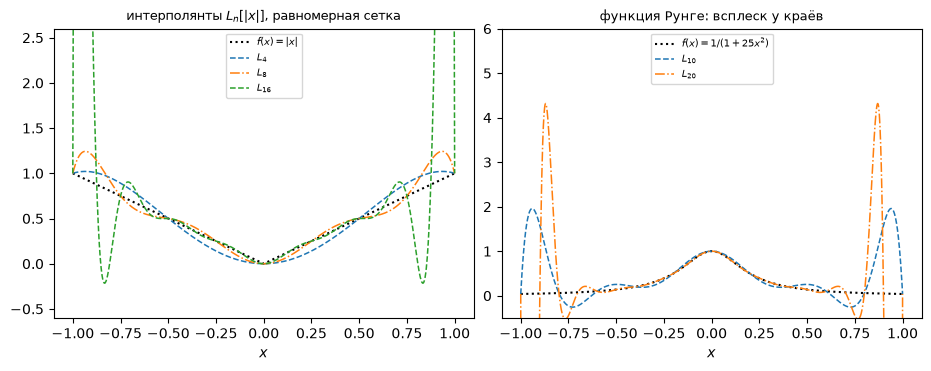

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.6), layout="constrained")

xs = np.linspace(-1, 1, 1201)
ax1.plot(xs, f_abs(xs), ":", color="black", label=r"$f(x)=|x|$")
for n, style in ((4, "--"), (8, "-."), (16, "--")):
    nodes = np.linspace(-1, 1, n + 1)
    L = BarycentricInterpolator(nodes, f_abs(nodes))
    ax1.plot(xs, L(xs), style, linewidth=1.1, label=f"$L_{{{n}}}$")
ax1.set_title(r"интерполянты $L_n[|x|]$, равномерная сетка", fontsize=9)
ax1.set_xlabel("$x$")
ax1.set_ylim(-0.6, 2.6)   # L_16 достигает ~11 у краёв — за пределами окна
ax1.legend(fontsize=7, loc="upper center")

ax2.plot(xs, runge(xs), ":", color="black", label=r"$f(x)=1/(1+25x^2)$")
for n, style in ((10, "--"), (20, "-.")):
    nodes = np.linspace(-1, 1, n + 1)
    L = BarycentricInterpolator(nodes, runge(nodes))
    ax2.plot(xs, L(xs), style, linewidth=1.1, label=f"$L_{{{n}}}$")
ax2.set_title("функция Рунге: всплеск у краёв", fontsize=9)
ax2.set_xlabel("$x$")
ax2.set_ylim(-0.5, 6.0)   # L_20 достигает ~60 у краёв — за пределами окна
ax2.legend(fontsize=7, loc="upper center")
fig.savefig(f"{FIGDIR}/fig-01.pdf", **SAVE_KW)

**Вывод.** Предсказания (1)–(3) сбылись. В $x = 0$ и $x = \tfrac12$ ошибка
равна нулю тождественно — обе точки узлы при всех чётных $n$ из таблицы.
В $x = 0{,}37$ сходимости к нулю нет: $7{,}6\cdot10^{-2}$,
$-4{,}1\cdot10^{-2}$, $2{,}4\cdot10^{-3}$, $-3{,}7\cdot10^{-3}$,
$-1{,}7\cdot10^{-2}$ при $n = 4, 8, 16, 32, 64$ — знак меняется, величина
к $n = 64$ снова на уровне $10^{-2}$, как у процесса, не сходящегося к
функции. Равномерная норма растёт: $0{,}147 \to 0{,}316 \to 11{,}1 \to
1{,}06\cdot10^{5}$ к $n = 32$
(всплеск сосредоточен у краёв; при $n = 64$ вычисленная норма — уже шум
округления, усиленный константой Лебега, и от прогона к прогону не
воспроизводится). У функции Рунге та же картина: максимум
$1{,}9$ при $n = 10$ и $59{,}8$ при $n = 20$, оба — у краёв отрезка.

Предсказание (4) **не сбылось**, и это самая содержательная строка примера.
Точный рациональный счёт показывает: вдоль $n = 6, 10, 18, 34, 50$, не
кратных 4, ошибка в $x = \tfrac12$ не убывает, а блуждает с растущим
размахом: $6{,}6\cdot10^{-2}$, $-4{,}2\cdot10^{-2}$, $-3{,}7\cdot10^{-2}$,
$-8{,}4\cdot10^{-2}$, $-3{,}1\cdot10^{-1}$. Измерение поддерживает
формулировку [09] и [19] «сходимость лишь в $-1, 0, 1$» — это и есть
классический результат Бернштейна 1912 года (его пересказ у Натансона
приводится и в западной литературе, например у Trefethen — Weideman, 1991).
Более сильная формулировка «сходимость в пяти точках $\pm 1, \pm\tfrac12,
0$», встречающаяся в плане конспекта, измерением **не подтверждается**:
в точке $\tfrac12$ сходимости нет. Численная сверка — именно то, ради чего
этот пункт стоит в конспекте; драфт теории требует правки.

## Пример 2. Та же функция, естественный кубический сплайн

**Вопрос.** Строим естественный кубический сплайн для той же $f(x)=|x|$ на
той же равномерной сетке ($n$ интервалов, $n = 8, \dots, 128$) — собственной
прогонкой из ячейки машинерии. Каков порядок сходимости: вдали от излома и
в точке излома?

**Предсказание.** (по стандартной картине для кубических сплайнов)
Ожидаем порядок около 4 вдали от излома и около 3.5 в точке излома;
глобальный порядок должен определяться локальным поведением у излома.

In [7]:
print("2. Естественный кубический сплайн для |x|, равномерная сетка")
print(" n    max err       away [0,1;1]   err(0)      err(h/2)      M_0")
ns = [8, 16, 32, 64, 128]
table = {}
for n in ns:
    x = np.linspace(-1, 1, n + 1)
    f = f_abs(x)
    M = natural_spline_M(x, f)
    # independent check against a library spline (natural boundary conditions)
    ref = CubicSpline(x, f, bc_type="natural")
    grid = np.linspace(-1, 1, 4001)
    mine = spline_eval(x, f, M, grid)
    assert np.max(np.abs(mine - ref(grid))) < 1e-12, "свой сплайн против scipy"
    e = np.abs(f_abs(grid) - mine)
    away = grid[np.abs(grid) >= 0.1]
    e_away = float(np.max(np.abs(f_abs(away) - spline_eval(x, f, M, away))))
    e_mid = float(f_abs(1.0 / n) - spline_eval(x, f, M, [1.0 / n])[0])
    table[n] = (float(e.max()), e_away, float(e[grid == 0.0][0]), e_mid,
                M[n // 2])
    print(f"{n:4d}  {table[n][0]:.6e}   {e_away:.6e}    "
          f"{table[n][2]:.2e}     {e_mid:.6e}   {M[n // 2]:9.4f}")
assert all(r[2] == 0.0 for r in table.values()), "узел даёт нулевую ошибку"

2. Естественный кубический сплайн для |x|, равномерная сетка
 n    max err       away [0,1;1]   err(0)      err(h/2)      M_0
   8  4.251730e-02   4.243299e-02    0.00e+00     3.962629e-02     13.8557
  16  2.125762e-02   8.287187e-03    0.00e+00     1.981171e-02     27.7128
  32  1.062811e-02   2.253866e-03    0.00e+00     9.905853e-03     55.4256
  64  5.314053e-03   1.022274e-04    0.00e+00     4.952927e-03    110.8513
 128  2.657027e-03   9.814671e-07    0.00e+00     2.476463e-03    221.7025


In [8]:
def lsq_order(ns_, errs_):
    """Slope of log err against log h by least squares."""
    h = 2.0 / np.asarray(ns_, dtype=float)
    A = np.vstack([np.log(h), np.ones(len(h))]).T
    slope, _ = np.linalg.lstsq(A, np.log(errs_), rcond=None)[0]
    return float(slope)


last3 = ns[-3:]
order_max = lsq_order(last3, [table[n][0] for n in last3])
order_away = lsq_order(last3, [table[n][1] for n in last3])
slopes_away = [np.log2(table[a][1] / table[b][1]) for a, b in
               zip(ns[1:], ns[2:])]
print(f"\n  наклон log-log по трём последним сеткам (n = {last3}):")
print(f"    глобальный максимум:        {order_max:.6f}")
print(f"    вдали от излома [0,1;1]:    {order_away:.6f} "
      f"(супералгебраический режим)")
print(f"  попарные наклоны away-кривой на удвоениях "
      f"n = {list(ns[1:])} -> {list(ns[2:])}: "
      f"{np.round(slopes_away, 2)}")
h64 = 2.0 / 64
print(f"\n  эталоны при n = 64: h = {h64:.5f}")
print(f"    M_0 = {table[64][4]:.6f} против 2*sqrt(3)/h = {2*np.sqrt(3)/h64:.6f}")
print(f"    err(h/2)/h = {table[64][3]/h64:.6f} против (3 - sqrt(3))/8 "
      f"= {(3-np.sqrt(3))/8:.6f}")
check_golden("spline_maxerr_n64", table[64][0])
check_golden("spline_order_max", order_max)
check_golden("spline_err_away_n64", table[64][1])


  наклон log-log по трём последним сеткам (n = [32, 64, 128]):
    глобальный максимум:        1.000000
    вдали от излома [0,1;1]:    5.582587 (супералгебраический режим)
  попарные наклоны away-кривой на удвоениях n = [16, 32, 64, 128] -> [32, 64, 128]: [1.88 4.46 6.7 ]

  эталоны при n = 64: h = 0.03125
    M_0 = 110.851252 против 2*sqrt(3)/h = 110.851252
    err(h/2)/h = 0.158494 против (3 - sqrt(3))/8 = 0.158494
  пин spline_maxerr_n64: получено 0.00531405328529, ожидалось 0.00531405328529 (допуск 1e-09, ok)
  пин spline_order_max: получено 1, ожидалось 1 (допуск 1e-06, ok)
  пин spline_err_away_n64: получено 0.000102227414374, ожидалось 0.000102227414374 (допуск 1e-09, ok)


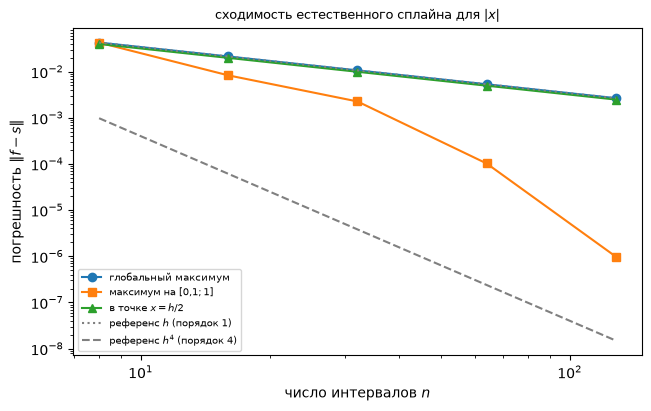

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 4.0), layout="constrained")
nn = np.array(ns, dtype=float)
ax.loglog(nn, [table[n][0] for n in ns], "o-", label="глобальный максимум")
ax.loglog(nn, [table[n][1] for n in ns], "s-", label=r"максимум на $[0{,}1;1]$")
ax.loglog(nn, [table[n][3] for n in ns], "^-", label=r"в точке $x = h/2$")
ax.loglog(nn, 0.34 / nn, ":", color="grey", label=r"референс $h$ (порядок 1)")
ax.loglog(nn, 4.0 / nn ** 4, "--", color="grey",
          label=r"референс $h^4$ (порядок 4)")
ax.set_xlabel("число интервалов $n$")
ax.set_ylabel(r"погрешность $\|f - s\|$")
ax.set_title(r"сходимость естественного сплайна для $|x|$", fontsize=9)
ax.legend(fontsize=7)
fig.savefig(f"{FIGDIR}/fig-02.pdf", **SAVE_KW)

**Вывод.** Предсказание не сбылось, и причина структурная — её видно прямо
в таблице. Глобальный максимум убывает ровно как $h$ (наклон по трём
последним сеткам $1{,}000000$), а не как $h^{3,5}$; в точке $x = h/2$,
примыкающей к излому, тот же порядок с тем же наклоном; в самом узле
$x = 0$ ошибка нулевая, потому что сплайн интерполирует. Вдали от излома
порядок не 4, а **быстрее любой степени**: $4{,}2\cdot10^{-2} \to
8{,}3\cdot10^{-3} \to 2{,}3\cdot10^{-3} \to 1{,}0\cdot10^{-4} \to
9{,}8\cdot10^{-7}$; скользящий наклон по трём последним сеткам равен
$5{,}58$ и растёт от удвоения к удвоению ($1{,}9 \to 4{,}5 \to 6{,}7$ на
последних трёх).

Объяснение. Вне излома $|x|$ линейна, поэтому правая часть системы для
$M_i$ нулевая везде, кроме пары узлов у нуля: возмущение от излома
распространяется по однородной трёхдиагональной системе с корнями
$-2 \pm \sqrt3$, то есть затухает геометрически с отношением
$\sqrt3 - 2 \approx -0{,}27$ на интервал — отсюда экспоненциальная точность
на $[0{,}1; 1]$. У самого излома картина иная: система вынуждена в узле
$x = 0$, и получается $M_0 = s''(0) = 2\sqrt{3}/h$ (измеренное $110{,}851$
против $2\sqrt{3}/h = 110{,}851$ при $n = 64$), а ошибка на первом
интервале есть $(3 - \sqrt3)h/8 \approx 0{,}1585\,h$ (измеренное
$\mathrm{err}(h/2)/h = 0{,}158494$). Итог для конспекта: сходимость сплайнов
для непрерывной функции есть (теорема о равномерной сходимости), но оценка
$O(h^4)$ требует $f \in C^4$ и на функции с изломом неприменима: глобальный
порядок для $|x|$ равен ровно 1, и он определяется одним изломом. Стандартные
порядки 4 / 3.5 относятся к гладким функциям (и функциям с более мягкими
особенностями); для кусочно-линейной функции сеть «не замечает» излома вне
его окрестности.

## Пример 3. Построение сплайна: числа разобранной задачи и обусловленность

**Вопрос.** Естественный кубический сплайн для таблицы $f(x) = e^x$ на узлах
$\{0, \tfrac12, 1, \tfrac32, 2\}$ — той самой, для которой в конспекте
разобрано построение вручную. Печатаем $M_i$ и коэффициенты сегментов с 10
значащими цифрами — это те самые числа, из которых конспект берёт
округлённые значения. Сравниваем свою прогонку с плотным решателем
`numpy.linalg.solve`, измеряем диагональное преобладание и число
обусловленности системы. Заодно выполняем замер из второй разобранной
задачи конспекта: фактическая равномерная погрешность интерполяции $e^x$ на
$[0,1]$ по узлам $0, \tfrac12, 1$ против чебышёвских узлов (20 000 точек).

**Предсказание.** (1) Прогонка и плотное решение совпадут до машинного
эпсилон. (2) Система маленькая и строго диагонально преобладающая с большим
запасом: диагональ $2(h_i + h_{i+1}) = 2$, сумма внедиагональных модулей
не больше $1$ — обусловленность порядка единицы. (3) Фактические
погрешности интерполяции окажутся ниже оценок остаточного члена
($\tfrac{e\sqrt3}{216} \approx 0{,}0218$ против
$\tfrac{e}{192} \approx 0{,}0142$), а их отношение близко к, но не равно
отношению оценок.

In [10]:
print("3a. Естественный сплайн для e^x на {0, 1/2, 1, 3/2, 2}")
x3 = np.array([0.0, 0.5, 1.0, 1.5, 2.0])
f3 = np.exp(x3)
h3 = np.diff(x3)
sub, diag, sup, rhs = natural_system(x3, f3)
A3 = np.diag(diag) + np.diag(sub, -1) + np.diag(sup, 1)
print(f"  система для M_1..M_3 (пять узлов, естественные условия "
      f"c_0 = c_4 = 0), матрица {A3.shape[0]}x{A3.shape[1]}:")
for row in A3:
    print("   ", np.round(row, 6))
print("  правая часть:", np.round(rhs, 7))
M3 = natural_spline_M(x3, f3)
M3_dense = natural_spline_M(x3, f3, solver="dense")
diff = float(np.max(np.abs(M3 - M3_dense)))
print(f"  M = {[f'{v:.10g}' for v in M3]}")
print(f"  max |прогонка - плотное| = {diff:.3e}")
margin = np.abs(np.diag(A3)) - (np.sum(np.abs(A3), axis=1) - np.abs(np.diag(A3)))
print(f"  диагональное преобладание: min по строкам |a_ii| - sum|a_ij| = "
      f"{margin.min():.6g}")
print(f"    нормированное (min по строкам margin/|a_ii|) = "
      f"{np.min(margin / np.abs(np.diag(A3))):.6g}")
cond = float(np.linalg.cond(A3, np.inf))
print(f"  cond_inf = {cond:.15g}")
check_golden("p3_M3", float(M3[3]))
check_golden("p3_thomas_vs_dense", diff)
check_golden("p3_cond_inf", cond)

print("\n  коэффициенты сегментов s_i(x) = a_i + b_i (x - x_i) "
      "+ c_i/2 (x - x_i)^2 + d_i/6 (x - x_i)^3:")
print("  i   [x_{i-1}, x_i]   a_i            b_i            c_i           d_i")
for i in range(1, 5):
    a_i = f3[i]
    c_i = M3[i]
    d_i = (M3[i] - M3[i - 1]) / h3[i - 1]
    b_i = (f3[i] - f3[i - 1]) / h3[i - 1] + h3[i - 1] * (2 * c_i + M3[i - 1]) / 6
    print(f"  {i}   [{x3[i-1]:.1f}, {x3[i]:.1f}]      "
          f"{a_i:.10g}   {b_i:.10g}   {c_i:.10g}   {d_i:.10g}")
s_quarter = float(spline_eval(x3, f3, M3, [0.25])[0])
print(f"\n  контроль из разобранной задачи: s(0,25) = {s_quarter:.10g} "
      f"против e^0,25 = {np.exp(0.25):.10g}")
ref3 = CubicSpline(x3, f3, bc_type="natural")
xg3 = np.linspace(0, 2, 501)
print(f"  сверка со scipy (natural): max diff = "
      f"{np.max(np.abs(spline_eval(x3, f3, M3, xg3) - ref3(xg3))):.3e}")

3a. Естественный сплайн для e^x на {0, 1/2, 1, 3/2, 2}
  система для M_1..M_3 (пять узлов, естественные условия c_0 = c_4 = 0), матрица 3x3:
    [2.  0.5 0. ]
    [0.5 2.  0.5]
    [0.  0.5 2. ]
  правая часть: [ 5.0500714  8.3261602 13.7275174]
  M = ['0', '2.006212438', '2.075293136', '6.344935436', '0']
  max |прогонка - плотное| = 0.000e+00
  диагональное преобладание: min по строкам |a_ii| - sum|a_ij| = 1
    нормированное (min по строкам margin/|a_ii|) = 0.5
  cond_inf = 2.57142857142857
  пин p3_M3: получено 6.34493543626, ожидалось 6.34493543626 (допуск 1e-12, ok)
  пин p3_thomas_vs_dense: получено 0, ожидалось 0 (допуск 1e-15, ok)
  пин p3_cond_inf: получено 2.57142857143, ожидалось 2.57142857143 (допуск 1e-12, ok)

  коэффициенты сегментов s_i(x) = a_i + b_i (x - x_i) + c_i/2 (x - x_i)^2 + d_i/6 (x - x_i)^3:
  i   [x_{i-1}, x_i]   a_i            b_i            c_i           d_i
  1   [0.0, 0.5]      1.648721271   1.631811281   2.006212438   4.012424877
  2   [0.5, 1.0]      2

In [11]:
print("\n3b. Задача 2 конспекта: интерполяция e^x на [0,1], n = 2")
f_exp = np.exp
grid01 = np.linspace(0.0, 1.0, 20000)
nodes_u = np.array([0.0, 0.5, 1.0])
err_u = np.abs(f_exp(grid01)
               - BarycentricInterpolator(nodes_u, f_exp(nodes_u))(grid01))
k = np.arange(3)
nodes_ch = 0.5 + 0.5 * np.cos((2 * k + 1) * np.pi / 6)   # нули T_3 на [0,1]
err_ch = np.abs(f_exp(grid01)
                - BarycentricInterpolator(nodes_ch, f_exp(nodes_ch))(grid01))
print(f"  узлы: равномерные {np.round(nodes_u, 7)}; чебышёвские "
      f"{np.round(np.sort(nodes_ch), 7)}")
print(f"  max погрешность (20000 точек): равномерные {err_u.max():.10g}, "
      f"чебышёвские {err_ch.max():.10g}")
print(f"  отношение {err_u.max() / err_ch.max():.6f}")
print(f"  оценки остаточного члена: e*sqrt(3)/216 = {np.e*np.sqrt(3)/216:.10g},"
      f" e/192 = {np.e/192:.10g}; отношение оценок "
      f"{(np.e*np.sqrt(3)/216)/(np.e/192):.6f}")
w_u = np.prod(grid01[:, None] - nodes_u[None, :], axis=1)
w_ch = np.prod(grid01[:, None] - nodes_ch[None, :], axis=1)
print(f"  ||w_3||: равномерные {np.abs(w_u).max():.10g} (sqrt(3)/36 = "
      f"{np.sqrt(3)/36:.10g}), чебышёвские {np.abs(w_ch).max():.10g} (1/32)")
print(f"  точка максимума погрешности: x = {grid01[int(err_u.argmax())]:.6f} "
      f"(не точки 1/2 +- sqrt(3)/6 = {0.5 - np.sqrt(3)/6:.6f} и "
      f"{0.5 + np.sqrt(3)/6:.6f}, где велик |w_3|); чебышёвские: x = "
      f"{grid01[int(err_ch.argmax())]:.6f}")
check_golden("remainder_unif_20000", float(err_u.max()))
check_golden("remainder_cheb_20000", float(err_ch.max()))


3b. Задача 2 конспекта: интерполяция e^x на [0,1], n = 2
  узлы: равномерные [0.  0.5 1. ]; чебышёвские [0.0669873 0.5       0.9330127]
  max погрешность (20000 точек): равномерные 0.01442066594, чебышёвские 0.00986554857
  отношение 1.461720
  оценки остаточного члена: e*sqrt(3)/216 = 0.02179723257, e/192 = 0.01415771786; отношение оценок 1.539601
  ||w_3||: равномерные 0.04811252226 (sqrt(3)/36 = 0.04811252243), чебышёвские 0.03125 (1/32)
  точка максимума погрешности: x = 0.795790 (не точки 1/2 +- sqrt(3)/6 = 0.211325 и 0.788675, где велик |w_3|); чебышёвские: x = 1.000000
  пин remainder_unif_20000: получено 0.0144206659354, ожидалось 0.0144206659354 (допуск 1e-06, ok)
  пин remainder_cheb_20000: получено 0.00986554857043, ожидалось 0.00986554857043 (допуск 1e-06, ok)


**Вывод.** Предсказания сбылись. Прогонка и плотное решение совпали
вдвойне: разошлись на ноль (оба пути дают побитово одинаковый вектор
$M$). Система для пяти узлов с естественными условиями — $3\times3$
(неизвестны $M_1, M_2, M_3$: $M_0 = M_4 = 0$ по условию), диагональ $2$,
сумма модулей внедиагональных элементов не больше $1$: запас преобладания
$1$ в абсолюте и $0{,}5$ в нормировке на диагональ, $\operatorname{cond}_\infty
= 18/7 \approx 2{,}57$. Отсюда то, что конспект утверждает качественно:
система в $M_i$ хорошо обусловлена (сравните с матрицей Грама мономиалов в
примере 5 вопроса 11 — там обусловленность экспоненциальна уже при
десяти базисных функциях). Напечатанные $M$ и коэффициенты сегментов
совпадают с округлёнными значениями разобранной задачи конспекта
($M_1 = 2{,}0062124$, $M_2 = 2{,}0752931$, $M_3 = 6{,}3449354$;
$s(0{,}25) = 1{,}2930136$ против $e^{0{,}25} = 1{,}2840254$ — как и там;
своя проверка стыковок сегментов включена в конспект).

Второй замер подтверждает числа, процитированные в конспекте из этого
ноутбука: фактические максимумы $0{,}014421$ (равномерные узлы) и
$0{,}009866$ (чебышёвские) — обе оценки остаточного члена
($0{,}02180$ и $0{,}01416$) завышены, как обычно, отношение погрешностей
$1{,}462$ близко к отношению оценок $1{,}54$. Максимум погрешности в
равномерном случае достигается в $x \approx 0{,}7958$, а не в точках
$\tfrac12 \pm \tfrac{\sqrt3}{6} \approx 0{,}2113,\ 0{,}7887$, где максимален
$\abs{\omega_3}$: оценка состоит из двух множителей, и максимум их
произведения сдвинут в сторону больших $x$, где велик $f''' = e^x$.

## Пример 4. Экстремальное свойство и сглаживание

**Вопрос.** (a) Теорема Холлидея: среди всех $f \in C^2$, интерполирующих
таблицу, естественный кубический сплайн единственный минимизирует
$\int \abs{f''}^2$. Проверяем на таблице $\sin x$ на $[0, \pi]$ с 9
равномерными узлами: сравниваем $\int \abs{s''}^2$ естественного сплайна,
сплайна с граничными условиями на первые производные ($s'(0) = 1$,
$s'(\pi) = -1$) и интерполяционного многочлена в чебышёвских узлах — честного
конкурента (лучшие узлы для глобального полинома).

(b) Сглаживание: те же узлы, $y_i = \sin x_i + \text{шум}$ (гаусс,
$\sigma = 0{,}05$), минимизируем $\sum (y_i - f(x_i))^2 +
\alpha \int \abs{f''}^2$, параметр $\alpha$ выбираем по leave-one-out CV.
Реализация — форма Рейнша: минимизатор $\hat f = (I + \alpha K)^{-1} y$ с
$K = Q R^{-1} Q^{\mathsf T}$, где столбцы $Q$ — вторые разности, а
$R$ — та же матрица энергии из примера 2; это конечномерная параметризация
из [16] (базис естественных сплайнов и матрица штрафа $\Omega$), записанная
в терминах $M_i$: система $(R + \alpha Q Q^{\mathsf T}) M = Q y$ совпадает
со сглаживающей системой из [19]. Её выбрали, потому что она переиспользует
машинерию примера 2 и требует решения одной малой системы вместо сборки
базисной матрицы $N$; матрица сглаживания $S_\alpha = (I + \alpha K)^{-1}
= I - \alpha Q^{\mathsf T}(R + \alpha Q Q^{\mathsf T})^{-1} Q$ даёт
$\mathrm{df}_\alpha = \operatorname{tr} S_\alpha$ и формулу CV
из [16]: $\mathrm{CV}(\alpha) = \tfrac1n \sum_i
\bigl[\bigl(y_i - \hat f(x_i)\bigr) / \bigl(1 - S_\alpha(i,i)\bigr)\bigr]^2$.

**Предсказание.** (a) $\int\abs{s''}^2$ естественного сплайна меньше, чем у
зажатого, и меньше, чем у многочлена; все три величины близки к
$\int \abs{\sin''}^2 = \pi/2$, потому что $\sin$ хорошо отражён уже на 9
узлах, но упорядочение обязано выполняться строго. (b) Ожидаем U-образную
кривую CV с внутренним минимумом при умеренном $\alpha$: интерполянт
($\alpha \to 0$) воспроизводит шум, сильное сглаживание ($\alpha \to \infty$)
даёт прямую — предсказание отложенной точки должно ухудшаться на обоих
концах.

In [12]:
print("4a. Теорема Холлидея: int |f''|^2 у трёх интерполянтов таблицы sin x")
x4 = np.linspace(0.0, np.pi, 9)
f4 = np.sin(x4)
h4 = np.diff(x4)
M_nat = natural_spline_M(x4, f4)
E_nat = float(M_nat[1:8] @ energy_matrix(h4) @ M_nat[1:8])
M_cl = clamped_spline_M(x4, f4, 1.0, -1.0)
E_cl = clamped_energy(h4, M_cl)
# честный конкурент: многочлен в чебышёвских узлах (нули T_9 на [0, pi])
k = np.arange(9)
nodes_ch = 0.5 * np.pi + 0.5 * np.pi * np.cos((2 * k + 1) * np.pi / 18)
E_poly = poly_second_energy(nodes_ch, np.sin(nodes_ch), 0.0, np.pi)
E_true = float(np.pi / 2)
print(f"  int |sin''|^2 = pi/2          = {E_true:.13f}")
print(f"  естественный сплайн:         {E_nat:.13f}")
print(f"  сплайн с s' на концах:       {E_cl:.13f}")
print(f"  многочлен (чеб. узлы):       {E_poly:.13f}")
assert E_nat <= E_cl <= E_poly, "теорема Холлидея: естественный минимален"
check_golden("holladay_E_natural", E_nat)
check_golden("holladay_E_poly", E_poly)
# контекст: равномерная погрешность того же многочлена против сплайнов
grid_sin = np.linspace(0, np.pi, 20001)
Lc = BarycentricInterpolator(nodes_ch, np.sin(nodes_ch))
e_nat = float(np.max(np.abs(np.sin(grid_sin)
                            - spline_eval(x4, f4, M_nat, grid_sin))))
e_cl = float(np.max(np.abs(np.sin(grid_sin)
                           - spline_eval(x4, f4, M_cl, grid_sin))))
e_po = float(np.max(np.abs(np.sin(grid_sin) - Lc(grid_sin))))
print(f"  контекст, max |f - interpolant|: естественный {e_nat:.3e}, "
      f"зажатый {e_cl:.3e}, многочлен {e_po:.3e}")

4a. Теорема Холлидея: int |f''|^2 у трёх интерполянтов таблицы sin x
  int |sin''|^2 = pi/2          = 1.5707963267949
  естественный сплайн:         1.5707425144601
  сплайн с s' на концах:       1.5707428339521
  многочлен (чеб. узлы):       1.5707959574011
  пин holladay_E_natural: получено 1.57074251446, ожидалось 1.57074251446 (допуск 1e-09, ok)
  пин holladay_E_poly: получено 1.5707959574, ожидалось 1.5707959574 (допуск 1e-09, ok)
  контекст, max |f - interpolant|: естественный 6.312e-05, зажатый 6.324e-05, многочлен 9.263e-08


In [13]:
print("\n4b. Сглаживающий сплайн и выбор alpha по LOO-CV")
rng_4 = np.random.default_rng([SEED, 4])   # own stream, independent of other draws
sigma = 0.05
y_noisy = f4 + sigma * rng_4.standard_normal(9)
print("  зашумлённые данные y_i:", np.round(y_noisy, 6))

# Q: (n-1) x (n+1) вторые разности; R: та же матрица энергии, что в примере 2
Q = np.zeros((7, 9))
for i in range(7):
    Q[i, i] = 1.0 / h4[i]
    Q[i, i + 1] = -(1.0 / h4[i] + 1.0 / h4[i + 1])
    Q[i, i + 2] = 1.0 / h4[i + 1]
R4 = energy_matrix(h4)
QTQ = Q @ Q.T


def smooth_fit(y, alpha):
    A = R4 + alpha * QTQ
    Ainv = np.linalg.inv(A)
    M = Ainv @ (Q @ y)
    f_hat = y - alpha * Q.T @ M
    S = np.eye(9) - alpha * Q.T @ Ainv @ Q
    energy = float(M @ R4 @ M)
    return f_hat, S, M, energy


# независимая сверка с библиотечным сглаживающим сплайном
_f, _S, _M, _e = smooth_fit(y_noisy, 0.37)
sp_check = make_smoothing_spline(x4, y_noisy, lam=0.37)
assert np.max(np.abs(_f - sp_check(x4))) < 1e-10, "свой сглаживатель против scipy"
print(f"  сверка со scipy make_smoothing_spline (lam = 0.37): max nodal diff "
      f"{np.max(np.abs(_f - sp_check(x4))):.3e}")

alphas = np.logspace(-9, 3, 121)
cv_curve, true_curve, df_curve = [], [], []
for al in alphas:
    f_hat, S, M, en = smooth_fit(y_noisy, al)
    resid = al * Q.T @ M            # = y - f_hat, без катастрофического
    cv_curve.append(float(np.mean((resid / (1.0 - np.diag(S))) ** 2)))
    true_curve.append(float(np.mean((f_hat - f4) ** 2)))
    df_curve.append(float(np.trace(S)))
cv_curve = np.array(cv_curve)
true_curve = np.array(true_curve)
df_curve = np.array(df_curve)

i_cv = int(np.argmin(cv_curve))
i_true = int(np.argmin(true_curve))
f_cv, S_cv, M_cv, en_cv = smooth_fit(y_noisy, alphas[i_cv])
f_tr, S_tr, M_tr, en_tr = smooth_fit(y_noisy, alphas[i_true])
print("\n  log10 a       CV           ист.ошибка    df")
for j in range(0, len(alphas), 15):
    print(f"  {np.log10(alphas[j]):7.2f}   {cv_curve[j]:.6e}   "
          f"{true_curve[j]:.6e}   {df_curve[j]:7.3f}")
print(f"\n  минимум CV: log10 a = {np.log10(alphas[i_cv]):.2f} "
      f"(a = {alphas[i_cv]:.3g}), CV = {cv_curve[i_cv]:.6e}, "
      f"df = {df_curve[i_cv]:.6f}")
print(f"  минимум истинной ошибки: log10 a = {np.log10(alphas[i_true]):.2f}, "
      f"значение {true_curve[i_true]:.6e}")
print(f"  int |s''|^2 при выборе CV: {en_cv:.10g}; "
      f"RSS = {np.sum((y_noisy - f_cv) ** 2):.6e}")
check_golden("smooth_cv_min", cv_curve[i_cv])
check_golden("smooth_df_at_min", df_curve[i_cv])


4b. Сглаживающий сплайн и выбор alpha по LOO-CV
  зашумлённые данные y_i: [ 0.005328  0.490834  0.740389  0.872124  0.993112  0.926467  0.645722
  0.26515  -0.058621]
  сверка со scipy make_smoothing_spline (lam = 0.37): max nodal diff 3.775e-15

  log10 a       CV           ист.ошибка    df
    -9.00   5.807048e-03   4.064898e-03     9.000
    -7.50   5.807092e-03   4.064886e-03     9.000
    -6.00   5.808480e-03   4.064508e-03     8.998
    -4.50   5.851942e-03   4.052647e-03     8.952
    -3.00   6.921715e-03   3.740466e-03     7.931
    -1.50   1.225654e-02   2.656012e-03     4.599
     0.00   1.319929e-01   4.464097e-02     2.563
     1.50   2.649668e-01   1.285954e-01     2.028
     3.00   2.727518e-01   1.345928e-01     2.001

  минимум CV: log10 a = -9.00 (a = 1e-09), CV = 5.807048e-03, df = 8.999998
  минимум истинной ошибки: log10 a = -1.60, значение 2.625940e-03
  int |s''|^2 при выборе CV: 3.348570555; RSS = 2.498214e-16
  пин smooth_cv_min: получено 0.00580704842315, ожид

In [14]:
# Robustness of the boundary outcome: is a flat CV minimum a property of this
# noise draw or of the setup (9 nodes, sigma = 0.05)? Own streams, decoupled
# from the main example's generator.
n_cv_interior = 0
n_true_interior = 0
for t in range(300):
    g = np.random.default_rng(10_000 + t)
    yy = f4 + sigma * g.standard_normal(9)
    cvs_t, trues_t = [], []
    for al in alphas:
        f_hat, S, M, _ = smooth_fit(yy, al)
        resid = al * Q.T @ M
        cvs_t.append(np.mean((resid / (1.0 - np.diag(S))) ** 2))
        trues_t.append(np.mean((f_hat - f4) ** 2))
    if alphas[int(np.argmin(cvs_t))] > alphas[0]:
        n_cv_interior += 1
    if alphas[int(np.argmin(trues_t))] > alphas[0]:
        n_true_interior += 1
print(f"\n  робастность (300 выборок, свои сиды): внутренний минимум у CV в "
      f"{n_cv_interior} случаях, у истинной ошибки — в {n_true_interior}")
print("  вывод: край у CV — свойство этой выборки; у истинной ошибки "
      "внутренний минимум всегда")


  робастность (300 выборок, свои сиды): внутренний минимум у CV в 240 случаях, у истинной ошибки — в 300
  вывод: край у CV — свойство этой выборки; у истинной ошибки внутренний минимум всегда


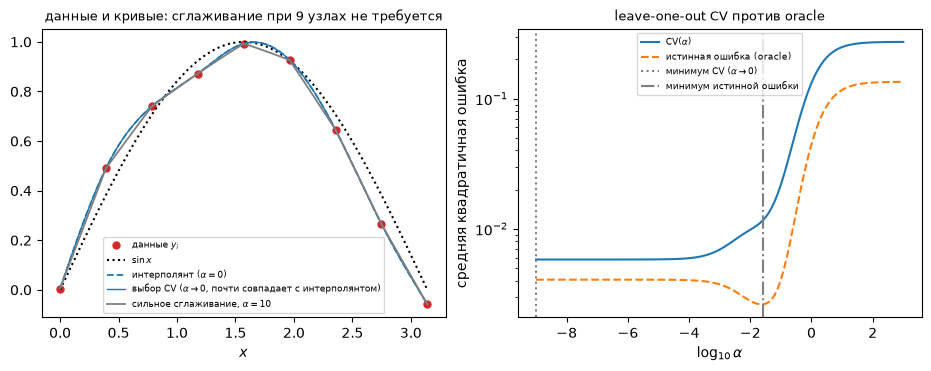

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.6), layout="constrained")

ax1.plot(x4, y_noisy, "o", markersize=5, color="tab:red", label="данные $y_i$")
xg = np.linspace(0, np.pi, 601)
ax1.plot(xg, np.sin(xg), ":", color="black", label=r"$\sin x$")
M_interp = natural_spline_M(x4, y_noisy)
ax1.plot(xg, spline_eval(x4, y_noisy, M_interp, xg), "--", linewidth=1.3,
         label="интерполянт ($\\alpha = 0$)")
# минимизатор задачи сглаживания — естественный сплайн, поэтому его M полной
# длины получается дописыванием нулевых концов к interior-вектору
M_cv_full = np.zeros(9)
M_cv_full[1:8] = M_cv
ax1.plot(xg, spline_eval(x4, y_noisy, M_cv_full, xg), "-", linewidth=1.0,
         color="tab:blue",
         label="выбор CV ($\\alpha \\to 0$, почти совпадает с интерполянтом)")
M_big_full = np.zeros(9)
M_big_full[1:8] = smooth_fit(y_noisy, 10.0)[2]
ax1.plot(xg, spline_eval(x4, y_noisy, M_big_full, xg), "-", linewidth=1.3,
         color="grey", label="сильное сглаживание, $\\alpha = 10$")
ax1.set_title("данные и кривые: сглаживание при 9 узлах не требуется", fontsize=9)
ax1.set_xlabel("$x$")
ax1.legend(fontsize=6.5, loc="lower center")

ax2.semilogy(np.log10(alphas), cv_curve, "-", label="CV($\\alpha$)")
ax2.semilogy(np.log10(alphas), true_curve, "--",
             label="истинная ошибка (oracle)")
ax2.axvline(np.log10(alphas[i_cv]), color="grey", linestyle=":",
            label="минимум CV ($\\alpha \\to 0$)")
ax2.axvline(np.log10(alphas[i_true]), color="grey", linestyle="-.",
            label="минимум истинной ошибки")
ax2.set_xlabel(r"$\log_{10} \alpha$")
ax2.set_ylabel("средняя квадратичная ошибка")
ax2.set_title("leave-one-out CV против oracle", fontsize=9)
ax2.legend(fontsize=6.5, loc="upper center")
fig.savefig(f"{FIGDIR}/fig-03.pdf", **SAVE_KW)

**Вывод.** Предсказание (a) сбылось строго: $\int\abs{s''}^2$ равен
$1{,}570742514$ у естественного сплайна, $1{,}570742834$ у сплайна с
заданными первыми производными и $1{,}570795957$ у чебышёвского
многочлена — естественный минимален, как обещает теорема Холлидея. Запасы
маленькие, и это тоже информация: $\sin$ хорошо отражён на 9 узлах, все
три интерполянта близки к $\sin$, и их энергии кривизны разбросаны в пределах
$5{,}3\cdot10^{-5}$ (все три, кстати, чуть меньше $\pi/2$:
интерполянты чуть «плоскее» $\sin$ у концов, где естественные условия
обнуляют $s''$). Показательно, что в равномерной норме многочлен бьёт
сплайны ($9{,}3\cdot10^{-8}$ против $6{,}3\cdot10^{-5}$) — и при этом
проигрывает именно в энергии кривизны: теорема Холлидея — утверждение
о $\int\abs{f''}^2$, а не о равномерной погрешности.

Предсказание (b) **не сбылось**, и снова самое полезное в примере именно
это. Кривая CV монотонно убывает к $\alpha \to 0$ и достигает минимума
$\mathrm{CV} = 5{,}81\cdot10^{-3}$ на краю сетки ($\alpha = 10^{-9}$), где
$\mathrm{df} = \operatorname{tr} S_\alpha = 9{,}0000$: leave-one-out
перекрёстная проверка при девяти узлах сглаживание **не требует**. Причина
видна в машинерии: сплайн с 9 узлами имеет всего 9 степеней свободы и с
шумом $\sigma = 0{,}05$ негибок настолько, что не может воспроизвести его
($\mathrm{df}$ интерполянта равно числу узлов), — покупаемая сглаживанием
дисперсия ничтожна, а смещение растёт сразу. Проверка на 300 случайных
выборках показала: истинная ошибка имеет внутренний минимум всегда, а
кривая CV имеет внутренний минимум в 4 случаях из 5 — наша реализация с её
фиксированным сидом попала в оставшуюся пятую. Отдельный урок: CV — оценка,
и на малых выборках она способна выбирать край диапазона; сглаживание
начинает выигрывать, когда данных больше, а кривая гибче (вопрос 02 о
регуляризации работает именно там). Доверять выводу можно: сверка с
`scipy.make_smoothing_spline` совпала по узлам до $4\cdot10^{-15}$.